# Code for Task 3 : Figure 2
What is the relationship between the distance a shot was taken and the chance it was a goal? Produce a figure for each season between 2018-19 to 2020-21 to answer this, and add it to your blog post along with a couple of sentences describing your figure. Has there been much change over the past three seasons? Why did you choose this figure?

https://seaborn.pydata.org/generated/seaborn.kdeplot.html#seaborn.kdeplot 

In [26]:
from ift6758.features import json2tidy

from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
#Copied from shot_style.ipynb
#List of the ids of each game
def games_ids(season):
    pathlist = Path(f"../notebooks/data/raw/{season}")
    return [p.stem for p in pathlist.glob("*.json")]

In [28]:
#Copied from shot_style.ipynb
# Put all the dataframes in a list and merge them into one dataframe
def games_list(season,games_ids):
    df_games_list = []

    for game_id in games_ids:
        df = json2tidy(f"../notebooks/data/raw/{season}/{game_id}.json")
        df_games_list.append(df)

    merged_df_regular = pd.concat(df_games_list, ignore_index=True)
    return merged_df_regular

In [ ]:
def distance(year) -> pd.DataFrame:
    """
    Function to add the column distance to the dataframe.
    Distance is the distance between the goal and the coordinates where the shot was taken

    Parameters:
        year (int) : Year of the season

    Returns:
        pd.DataFrame
    """
    df = games_list(year,games_ids(year))

    # team_defending: True is home_team, False is away_team
    # df["team_id"] contain "eventOwnerTeamId" which is the team associated with the action
    # df["team_id"] is the team that is trying to score
    df["team_defending"] = (df["team_id"] != df["homeTeam_id"])

    df["side_defending"] = df["homeTeamDefendingSide"]

    conditions = [df["side_defending"]=="right",df["side_defending"]=="left"]
    choices = ["left","right"]

    df["side_defending"] = np.where(df["team_defending"]==False,np.select(conditions,choices),df["side_defending"])
    
    # if right, goal_coor = (89,0)
    # else left, (-89,0)
    df["goalCoordX"] = np.where(df["side_defending"]=="right",89,-89)

    #calculate the distance between the x,y coordinates and the goal
    #the y coordinate for the goals is 0
    df["distance"] = np.sqrt((df["goalCoordX"]-df["x_coord"])**2 + df["y_coord"]**2)

    #Remove team_defending, side_defending, goalCoordX
    #Keep only the distance
    df = df.drop(
        columns = ["team_defending", "side_defending", "goalCoordX"]
    )

    return df


In [33]:
def figure2(season):
    """
    Function to draw kernel density estimate plot for the season specified

    Paramaters:
        season(int): Season to take de games from
    """
    df = distance(season)
    shot_or_goal = df[["distance","event_type"]] 

    shot = shot_or_goal[shot_or_goal["event_type"]=="shot-on-goal"]
    goal = shot_or_goal[shot_or_goal["event_type"]=="goal"]

    sns.kdeplot(shot["distance"], label="shots")
    sns.kdeplot(goal["distance"], label="goals")

    plt.title("Distance-goal relationship " + str(season))
    plt.legend()

    plt.savefig("distance_goal_" + str(season) + ".png")
    plt.show()

In the figure the blue line is the density of the shots by the distance and the orange line is the density of the goals by the distance.
After observing the figures, we can see that the density curves for 2018 are very different from the ones for 2019 and 2020.
It is because the plays in the 2018 json files don't have the key "homeTeamDefendingSide". This key is used in the code to determine to which side of the rink the shot is directed to.
There is not much change between the curves for 2019 and 2020. Those figures shows 

c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


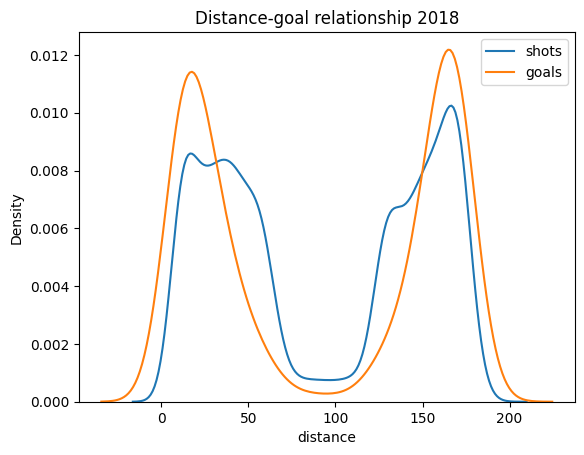

c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


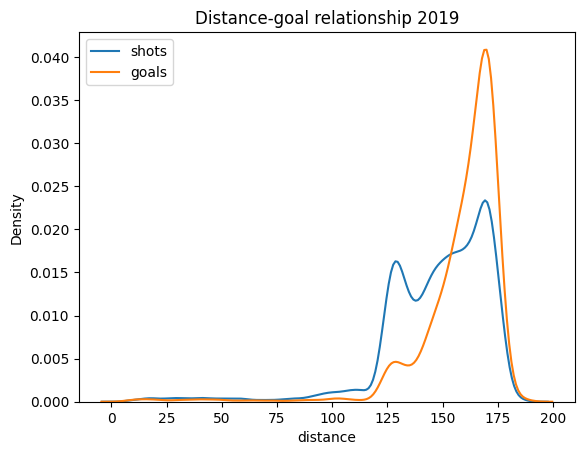

c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


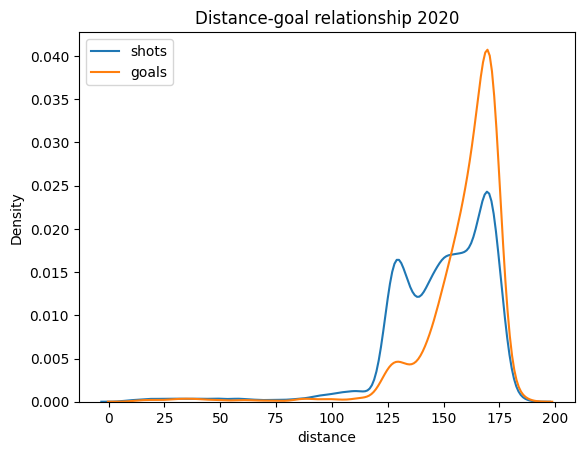

In [31]:
figure2(2018)
figure2(2019)
figure2(2020)